# Phase 9.3 - Búsqueda Máxima + Hybrid Final

Pipeline:
1. Búsqueda de hiperparámetros (`phase9.3`) con objetivo multi-métrica.
2. Reentrenamiento del mejor trial.
3. Híbrido final `phase9.3_hybrid` (clasificación de 9.3 + completitud de 9).


In [1]:
from pathlib import Path
import json
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('.')
P = ROOT / 'phases/phase09_multitask_patterns'

RUN_V93 = P / 'run_phase9_3_search_and_train_best.py'
RUN_V93H = P / 'run_phase9_3_hybrid_best_progress.py'

SUM_V93 = P / 'output_phase9_3_search_best_GBPUSD/GBPUSD_phase9_3_summary.json'
TRIALS_V93 = P / 'output_phase9_3_search_best_GBPUSD/GBPUSD_phase9_3_trials.csv'

SUM_V93H = P / 'output_phase9_3_hybrid_best_progress_GBPUSD/GBPUSD_phase9_3_hybrid_summary.json'
CMP_V93H = P / 'output_phase9_3_hybrid_best_progress_GBPUSD/GBPUSD_phase9_3_hybrid_model_comparison.csv'

In [2]:
subprocess.run(['python', str(RUN_V93)], check=True)
subprocess.run(['python', str(RUN_V93H)], check=True)
print('Ejecutado:', RUN_V93)
print('Ejecutado:', RUN_V93H)

Saved summary: ./phases/phase09_multitask_patterns/output_phase9_3_search_best_GBPUSD/GBPUSD_phase9_3_summary.json
Best trial: t1_balanced_reg
Best threshold: 0.55
Test metrics: {'acc': 0.6602977116196401, 'f1_macro_all': 0.5145809812689532, 'f1_macro_informative': 0.5814399721504264, 'recall_class0': 0.7417018708509354, 'mae_progress': 0.08718275278806686, 'rmse_progress': 0.11374282836914062, 'mae_progress_early': 0.07609598338603973, 'n_informative': 1187}


Saved summary: ./phases/phase09_multitask_patterns/output_phase9_3_hybrid_best_progress_GBPUSD/GBPUSD_phase9_3_hybrid_summary.json
Hybrid metrics: {'acc': 0.6602977116196401, 'f1_macro_all': 0.5145809812689532, 'f1_macro_informative': 0.5814399721504264, 'recall_class0': 0.7417018708509354, 'mae_progress': 0.062203552723980725, 'rmse_progress': 0.08788842853147247, 'mae_progress_early': 0.06172632650139467, 'n_informative': 1187}
Ejecutado: ./phases/phase09_multitask_patterns/run_phase9_3_search_and_train_best.py
Ejecutado: ./phases/phase09_multitask_patterns/run_phase9_3_hybrid_best_progress.py


In [3]:
s93 = json.loads(SUM_V93.read_text())
trials = pd.read_csv(TRIALS_V93)
s93h = json.loads(SUM_V93H.read_text())
cmp = pd.read_csv(CMP_V93H)

print('Best trial:', s93['best_trial']['name'])
print('Best threshold:', s93['best_threshold'])
print('Test metrics (v9.3):')
pd.DataFrame([s93['test_metrics']]).T.rename(columns={0:'v9.3'}).round(4)

Best trial: t1_balanced_reg
Best threshold: 0.55
Test metrics (v9.3):


,v9.3
acc,0.6603
f1_macro_all,0.5146
f1_macro_informative,0.5814
recall_class0,0.7417
mae_progress,0.0872
rmse_progress,0.1137
mae_progress_early,0.0761
n_informative,1187.0000


In [4]:
trials.sort_values('best_val_score', ascending=False).head(10).round(4)

,trial,name,lr,weight_decay,w_inf,w_sub,w_reg,pos_scale,label_smoothing_sub,best_val_thr,...,val_f1_macro_informative,val_recall_class0,val_mae_progress_early,test_score,test_acc,test_f1_macro_all,test_f1_macro_informative,test_recall_class0,test_mae_progress,test_mae_progress_early
0,t1_balanced_reg,t1_balanced_reg,0.0010,0.0001,1.0,1.10,0.9,1.00,0.03,0.450,...,0.6069,0.7543,0.1067,0.7675,0.6821,0.5355,0.5958,0.7695,0.0803,0.0829
1,t2_noise_guard,t2_noise_guard,0.0010,0.0001,1.2,1.00,0.8,1.20,0.00,0.575,...,0.5867,0.7437,0.1149,0.7403,0.6685,0.5208,0.5832,0.7565,0.0801,0.0919
2,t4_progress_push,t4_progress_push,0.0008,0.0002,1.0,1.10,1.2,1.00,0.03,0.525,...,0.5596,0.7610,0.1081,0.7303,0.6707,0.5071,0.5397,0.7670,0.0875,0.0717
3,t0_base,t0_base,0.0010,0.0001,1.0,1.00,0.7,1.00,0.00,0.525,...,0.4275,0.7841,0.1173,0.6667,0.6621,0.4725,0.4611,0.7849,0.1151,0.0825
4,t3_informative_push,t3_informative_push,0.0008,0.0001,0.9,1.30,1.0,0.85,0.05,0.500,...,0.3847,0.8176,0.1019,0.6370,0.6741,0.4541,0.3966,0.8177,0.0841,0.0783
5,t5_aggressive_mix,t5_aggressive_mix,0.0010,0.0002,1.1,1.25,1.0,0.90,0.02,0.525,...,0.0480,0.9444,0.0959,0.4045,0.7041,0.3038,0.0522,0.9445,0.1015,0.0755


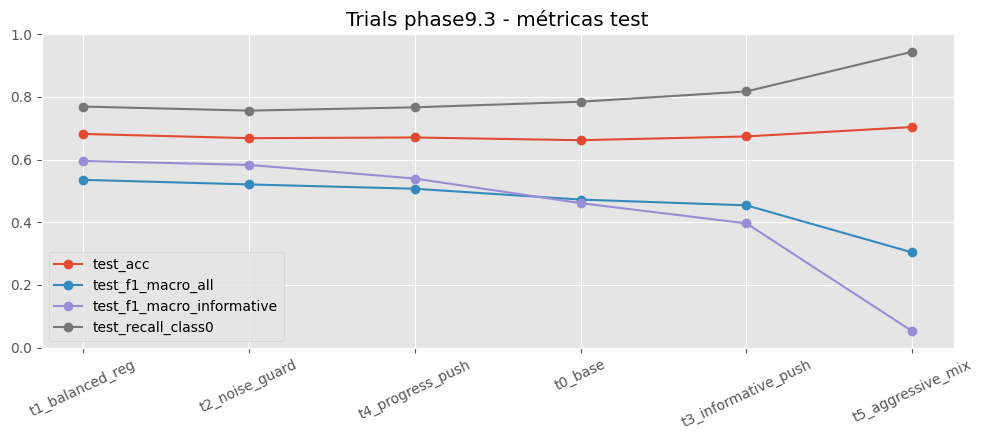

In [5]:
plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(10,4.5))
plot_cols = ['test_acc','test_f1_macro_all','test_f1_macro_informative','test_recall_class0']
t = trials.sort_values('best_val_score', ascending=False).reset_index(drop=True)
for c in plot_cols:
    ax.plot(t['trial'], t[c], marker='o', label=c)
ax.set_title('Trials phase9.3 - métricas test')
ax.set_ylim(0,1)
ax.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [6]:
cmp.round(4)

,model,acc,f1_macro_all,f1_macro_informative,mae_progress,rmse_progress,mae_progress_early,n_informative,recall_class0
0,phase9,0.3875,0.3922,0.7622,0.0622,0.0879,0.0617,1187,NaN
1,phase9_1,0.6532,0.5056,0.5640,0.0640,0.0917,0.0708,1187,0.7326
2,phase9_2_hybrid,0.6534,0.5060,0.5643,0.0622,0.0879,0.0617,1187,0.7330
3,phase9_3,0.6603,0.5146,0.5814,0.0872,0.1137,0.0761,1187,0.7417
4,phase9_3_hybrid_best_progress,0.6603,0.5146,0.5814,0.0622,0.0879,0.0617,1187,0.7417


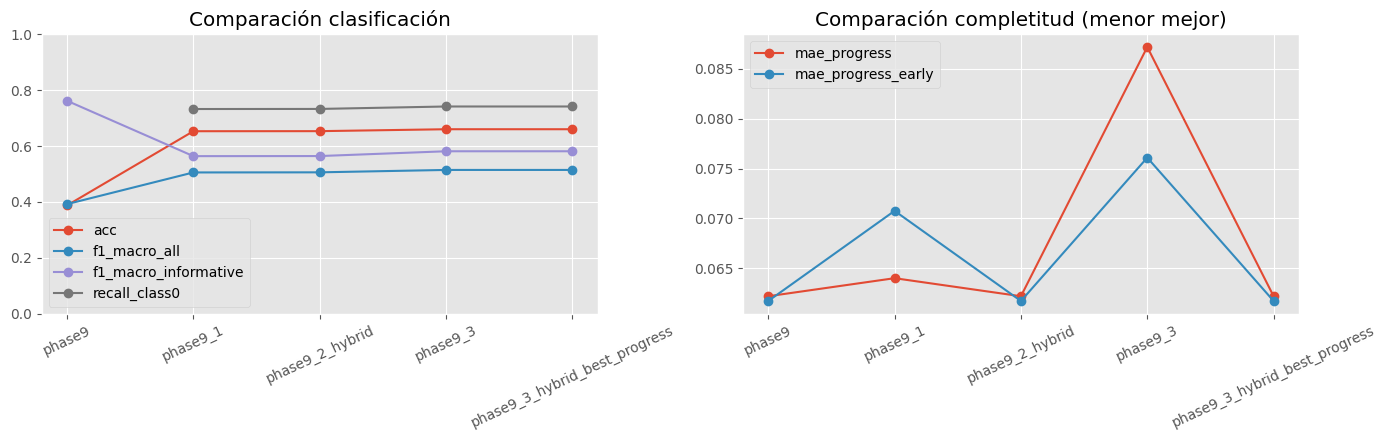

In [7]:
focus = cmp[cmp['model'].isin(['phase9','phase9_1','phase9_2_hybrid','phase9_3','phase9_3_hybrid_best_progress'])].copy()

fig, axes = plt.subplots(1,2,figsize=(14,4.5))

# higher better
cols_hi = ['acc','f1_macro_all','f1_macro_informative','recall_class0']
for c in cols_hi:
    axes[0].plot(focus['model'], focus[c], marker='o', label=c)
axes[0].set_ylim(0,1)
axes[0].set_title('Comparación clasificación')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=25)

# lower better
cols_lo = ['mae_progress','mae_progress_early']
for c in cols_lo:
    axes[1].plot(focus['model'], focus[c], marker='o', label=c)
axes[1].set_title('Comparación completitud (menor mejor)')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

## Lectura rápida

- `phase9.3`: máxima mejora en clasificación global y separación de ruido.
- `phase9.3_hybrid_best_progress`: conserva esa mejora de clasificación y recupera el mejor error de completitud.
